# 00 · Data tour: one field, from the label row to every model input

**Scope.** This notebook follows one real Malawi 2023 maize field through the whole data path: the yield label, the
field polygon, the Sentinel-2 chips, the cloud mask, the monthly table, and the exact input that each model receives
(location baseline, vegetation-index regression, GRU, MOSAIKS, Presto). **Nothing is trained.** It only reads files
that `scripts/imagery/download_sentinel2.py` and `scripts/models/get_presto.py` already wrote.

Before running, do the same setup as for `01_presto_first_run.ipynb`: `python -m pip install -e ".[dev,presto]"`,
`python scripts/models/get_presto.py`, and the ten pilot chips from `scripts/imagery/download_sentinel2.py`. The plots need matplotlib.

```
provider file ──audit──► screened CSV row (y = yield, lat/lon) + field polygon (GeoJSON)
                                  │
                lat/lon picks a 64 × 64 grid of 10 m pixels; the polygon picks the field pixels
                                  ▼
Sentinel-2 L2A scenes (Earth Search) ──► one chip per accepted month: 10 bands × 64 × 64
                                  │  SCL cloud mask ∩ field mask, median per band
                                  ▼
monthly field table: months × 10 bands
       │                      │                          │
 vegetation indices      GRU sequence               Presto encoder
 → ridge / RF / XGBoost  months × bands             → 128-number embedding → ridge or linear head
```

MOSAIKS is the only branch that starts from the chip images themselves, before the monthly table.

**Where each part of the 3D architecture explorer appears in this notebook**

| 3D explorer label | Section | Code |
|---|---|---|
| Measured harvest label | 3 | `yield_kg_ha` in the cohort table |
| Seasonal Sentinel-2 | 5, 6 | `read_chip` |
| Missing-data masks | 6, 8e | `Scene.valid`, `PrestoInputs.mask` |
| Monthly field summaries | 7 | `monthly_series` |
| Month / time / coordinates | 8e | `PrestoInputs.month`, `PrestoInputs.latlons` |
| Grouped monthly tokens | 8e | inside `Presto.encoder` |
| 2 temporal encoder blocks, native masked mean, final LayerNorm | 8e | `encode` |
| Linear regression head, regression loss | 9 | `construct_finetuning_model` (not trained here) |

Three numbers in the explorer differ from our data. It draws 12 months; a Malawi or Zimbabwe season has 9
(1 Oct – 30 Jun) and a Kenya season 8 (1 Feb – 30 Sep). It draws 73 tokens (6 × 12 + 1); a Malawi field has at most
6 × 9 + 1 = 55, and fewer when months are missing. It names QA60, an Earth Engine cloud band; we use the SCL class
layer that comes with Earth Search L2A.

In [1]:
import json
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from rasterio.transform import Affine
from rasterio.warp import transform_geom
from shapely.geometry import Point, shape

from cropyield import ROOT
from cropyield.data.cohorts import COHORTS, load_cohort
from cropyield.features.presto_inputs import MISSING_DYNAMIC_WORLD, NORMED_BANDS, presto_inputs
from cropyield.longpath import filesystem_path, path_exists
from cropyield.models.presto import encode, load_presto, to_tensors
from cropyield.models.presto_single_file import BANDS_GROUPS_IDX
from cropyield.satellite.chips import read_chip
from cropyield.satellite.monthly import month_range, monthly_series

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10})
IMAGERY = ROOT / "data" / "imagery" / "sentinel2"

## 1. The task in one sentence

For one maize field in one season, predict **y = yield in kg/ha** from **X = Sentinel-2 observations of that field
during that season**. RQ1 asks which *representation* of X predicts y best (vegetation indices, MOSAIKS features,
Presto embeddings), with the model on top (ridge, random forest, XGBoost, a linear head) kept as comparable as possible.
One row of every table below is one (field, season) pair.

## 2. Where the labels come from

Every cohort travels the same path:

1. **Provider file** in `data/raw/`, for example `data/raw/malawi/mwi_kas_lc_fo_202305_cc_yield.zip`
   (FAO / NASA Harvest crop-cut campaign, 2023).
2. **Audit** by `scripts/labels/audit_datasets.py`: units to kg/ha, coordinate and geometry checks, duplicates and flags.
   Output: `data/audit/<dataset>_screened_candidates.csv` (one row per observation) and, for Malawi,
   `data/audit/<dataset>_candidates_wgs84.geojson` with the field polygons. See `data/audit/report.html`.
3. **Cohort** by `load_cohort(name)` in `src/cropyield/data/cohorts.py`: one dataset, its years, country and
   management filter, plus the fixed season window per agro-zone (`docs/DECISIONS.md`, 25 Oct).

In [2]:
overview = []
for name, cohort_def in COHORTS.items():
    rows = load_cohort(name)
    overview.append({
        "cohort": name,
        "audit_file": f"{cohort_def.dataset}_screened_candidates.csv",
        "years": ", ".join(map(str, cohort_def.years)),
        "season_window": f"{date(2001, *cohort_def.season_start):%d %b} – {date(2001, *cohort_def.season_end):%d %b}",
        "rows": len(rows),
        "geometry": ", ".join(f"{kind} {n}" for kind, n in rows["geometry_type"].value_counts().items()),
        "median_yield_kg_ha": round(rows["yield_kg_ha"].median()),
        "zero_yield_share": round(float((rows["yield_kg_ha"] == 0).mean()), 3),
    })
pd.DataFrame(overview).set_index("cohort")

,audit_file,years,season_window,rows,geometry,median_yield_kg_ha,zero_yield_share
cohort,,,,,,,
malawi_2022,malawi_2022_screened_candidates.csv,2022,01 Oct – 30 Jun,529,"Polygon 447, MultiPolygon 82",2418,0.006
malawi_2023,malawi_2023_screened_candidates.csv,2023,01 Oct – 30 Jun,260,"Polygon 223, MultiPolygon 37",2440,0.000
kenya_oaf_2019_2020,one_acre_fund_full_screened_candidates.csv,"2019, 2020",01 Feb – 30 Sep,3977,Point 3977,2889,0.019
zimbabwe_lacuna_2022_2023,zimbabwe_screened_candidates.csv,"2022, 2023",01 Oct – 30 Jun,2266,Point 2266,2956,0.012
zimbabwe_2024,vision_guided_yield_estimation_screened_candid...,2024,01 Oct – 30 Jun,4332,Point 4332,93,0.433


What the table says:

* Only the two **Malawi** cohorts have **field polygons**. Kenya and both Zimbabwe cohorts have **points**: one GPS
  location per field, so their satellite value comes from one 10 m pixel (a 3 × 3 neighbourhood is an open decision
  in `docs/ROADMAP.md`).
* **Zimbabwe 2024** has a very high zero-yield share and a low median. Check those rows before they enter a model.
* **Malawi 2022** cannot be filled from Earth Search Collection 1 yet (`docs/DECISIONS.md`, 26 Oct).

## 3. One field: its label row

The field below is source row 4 of Malawi 2023, one of the ten pilot fields. Any other pilot `obs_id` works too.

In [3]:
cohort = load_cohort("malawi_2023")
FIELD = "malawi_2023:1d60c29e-ee3a-4639-9e07-0239523dfc62"
row = cohort.set_index("obs_id").loc[FIELD]
season = (date.fromisoformat(row["season_start"]), date.fromisoformat(row["season_end"]))
row[["source_row", "yield_field", "source_yield", "source_yield_units", "yield_kg_ha", "nested_subcut_yield_t_ha",
     "field_area_ha", "observation_time", "latitude", "longitude", "geometry_type", "season_start",
     "season_end"]].to_frame("value")

,value
source_row,4
yield_field,cc_ey_t
source_yield,3.31
source_yield_units,t/ha
yield_kg_ha,3310.0
nested_subcut_yield_t_ha,5.52
field_area_ha,0.8256
observation_time,2023/05/17 08:15:00.000
latitude,-13.289999
longitude,33.400767


* `yield_kg_ha` is the label **y**. It is the provider's crop-cut estimated yield (`yield_field` = `cc_ey_t`, in t/ha)
  times 1000.
* `observation_time` is the date of the crop cut, near harvest. It does **not** set the satellite window: the window
  is fixed per agro-zone (`season_start` .. `season_end`).
* `nested_subcut_yield_t_ha` is a second, smaller crop cut inside the same field. When it differs from the main cut,
  the label itself is noisy. The plot shows how much for the whole cohort.

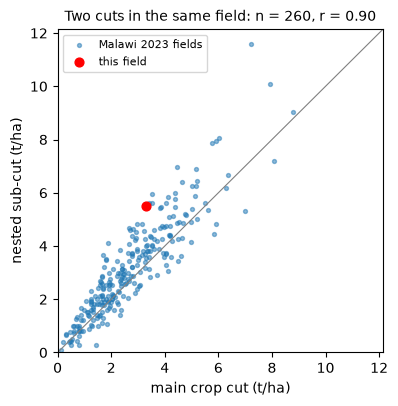

r² = 0.82 | sub-cut minus main cut: mean +0.45 t/ha, middle 50 % from -0.03 to +0.83 t/ha


In [4]:
cuts = pd.DataFrame({
    "main_cut_t_ha": cohort["yield_kg_ha"] / 1000,
    "nested_subcut_t_ha": pd.to_numeric(cohort["nested_subcut_yield_t_ha"].replace("", np.nan)),
}).dropna()
r = cuts.corr().iloc[0, 1]
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.scatter(cuts["main_cut_t_ha"], cuts["nested_subcut_t_ha"], s=8, alpha=0.5, label="Malawi 2023 fields")
ax.scatter(row["yield_kg_ha"] / 1000, float(row["nested_subcut_yield_t_ha"]), s=40, color="red", label="this field")
limit = [0, float(cuts.max().max()) * 1.05]
ax.plot(limit, limit, color="grey", lw=0.8)
ax.set(xlim=limit, ylim=limit, xlabel="main crop cut (t/ha)", ylabel="nested sub-cut (t/ha)",
       title=f"Two cuts in the same field: n = {len(cuts)}, r = {r:.2f}")
ax.legend(loc="upper left", fontsize=8)
plt.show()
difference = cuts["nested_subcut_t_ha"] - cuts["main_cut_t_ha"]
print(f"r² = {r ** 2:.2f} | sub-cut minus main cut: mean {difference.mean():+.2f} t/ha, "
      f"middle 50 % from {difference.quantile(0.25):+.2f} to {difference.quantile(0.75):+.2f} t/ha")

This gives a rough ceiling: a satellite model should not be expected to agree with the main cut much better than a
second cut of the same field does. Other cohorts have no second cut, so their ceiling is unknown.

## 4. Polygon and point: how the label meets the satellite

The CSV row holds a **point** (latitude, longitude). For Malawi, the field outline is a **polygon** in the GeoJSON
next to the audit CSV. The downloader uses them in two steps:

1. **The point picks the grid.** The longitude gives the UTM zone (here EPSG:32736, zone 36 south). The chip is
   64 × 64 pixels of 10 m, so 640 m × 640 m, centred on the point.
2. **The polygon picks the pixels.** It is drawn onto that grid as a mask. `aoi` keeps every pixel that the outline
   touches. `aoi_interior` keeps only the pixels whose centre is inside the field; the monthly table uses these.

chip grid       EPSG:32736 64 × 64 pixels of 10 m | top-left corner (m): 543080.0 8531070.0
field pixels    112 touched by the outline, 84 with centre inside → 0.84 ha vs field_area_ha 0.83
point in field  260 of 260 Malawi 2023 rows have their CSV point inside their own polygon


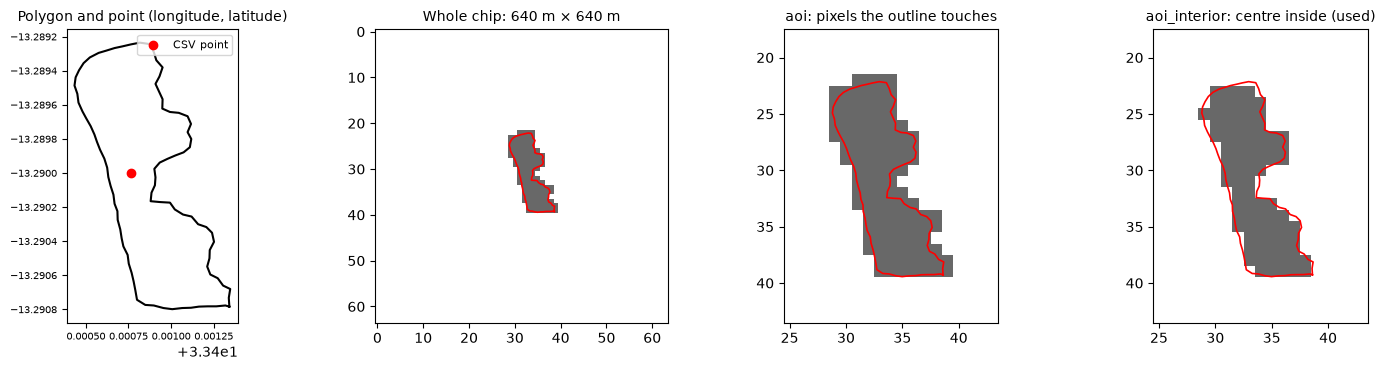

In [5]:
geojson = json.loads((ROOT / "data" / "audit" / "malawi_2023_candidates_wgs84.geojson").read_text(encoding="utf-8"))
polygons = {f["properties"]["source_id"]: f["geometry"] for f in geojson["features"]}
polygon = polygons[row["source_id"]]


def find_chip(dataset, source_id, season):
    """The downloaded chip of one field whose window covers the season; the one with most scenes if several runs."""
    chips = [read_chip(d) for d in sorted(IMAGERY.glob(f"run-*/records/{dataset}__{source_id}__*"))
             if path_exists(d / "record.json")]
    chips = [c for c in chips if c.start_date and c.end_date and c.start_date <= season[0] and c.end_date >= season[1]]
    if not chips:
        raise FileNotFoundError(f"no chip for {source_id}; run scripts/imagery/download_sentinel2.py for the pilot first")
    return max(chips, key=lambda c: len(c.scenes))


def pixel_outline(geometry, chip):
    """Polygon rings in chip pixel coordinates (column, row), ready to draw over imshow."""
    projected = shape(transform_geom("EPSG:4326", chip.crs, geometry))
    to_pixel = ~Affine(*chip.transform)
    parts = projected.geoms if projected.geom_type == "MultiPolygon" else [projected]
    rings = []
    for part in parts:
        columns, rows_ = zip(*(to_pixel * xy for xy in part.exterior.coords))
        rings.append((np.array(columns) - 0.5, np.array(rows_) - 0.5))  # imshow puts pixel centres on integers
    return rings


chip = find_chip(row["dataset"], row["source_id"], season)
outline = pixel_outline(polygon, chip)
inside = sum(shape(polygons[sid]).contains(Point(lon, lat))
             for sid, lon, lat in zip(cohort["source_id"], cohort["longitude"], cohort["latitude"]))
print("chip grid      ", chip.crs, f"{chip.aoi.shape[0]} × {chip.aoi.shape[1]} pixels of {chip.transform[0]:.0f} m",
      "| top-left corner (m):", chip.transform[2], chip.transform[5])
print("field pixels   ", int(chip.aoi.sum()), "touched by the outline,", int(chip.aoi_interior.sum()), "with centre inside",
      f"→ {chip.aoi_interior.sum() * 0.01:.2f} ha vs field_area_ha {float(row['field_area_ha']):.2f}")
print("point in field ", f"{inside} of {len(cohort)} Malawi 2023 rows have their CSV point inside their own polygon")


def draw_outline(ax, color="yellow"):
    for columns, rows_ in outline:
        ax.plot(columns, rows_, color=color, lw=1.2)


rows_in, cols_in = np.where(chip.aoi)
PAD = 4
ZOOM_X = (cols_in.min() - PAD - 0.5, cols_in.max() + PAD + 0.5)
ZOOM_Y = (rows_in.max() + PAD + 0.5, rows_in.min() - PAD - 0.5)

field_shape = shape(polygon)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for part in getattr(field_shape, "geoms", [field_shape]):
    axes[0].plot(*part.exterior.xy, color="black")
axes[0].scatter(row["longitude"], row["latitude"], color="red", zorder=3, label="CSV point")
axes[0].set(title="Polygon and point (longitude, latitude)", aspect="equal")
axes[0].tick_params(labelsize=7)
axes[0].legend(fontsize=8)
axes[1].imshow(chip.aoi, cmap="Greys", vmin=0, vmax=1.5)
draw_outline(axes[1], "red")
axes[1].set_title("Whole chip: 640 m × 640 m")
for ax, mask, title in [(axes[2], chip.aoi, "aoi: pixels the outline touches"),
                        (axes[3], chip.aoi_interior, "aoi_interior: centre inside (used)")]:
    ax.imshow(mask, cmap="Greys", vmin=0, vmax=1.5)
    draw_outline(ax, "red")
    ax.set(xlim=ZOOM_X, ylim=ZOOM_Y, title=title)
plt.tight_layout()
plt.show()

## 5. The satellite picture: one scene

A scene folder such as `S2B_T36LWL_20230307T081156_L2A` means: satellite Sentinel-2**B**, tile **36LWL** (a 110 km
grid square), 7 March 2023 at 08:11 UTC, processing level **L2A** (atmosphere corrected, bottom-of-atmosphere
reflectance). It holds three rasters on the chip grid:

| File | Content |
|---|---|
| `reflectance.tif` | 10 layers, one per band, 64 × 64 pixels. Unitless reflectance (0 = black, 1 = white); scale 0.0001 and offset −0.1 already applied once by the downloader. Pixels that are not clear are −9999 and read back as NaN. |
| `scl.tif` | ESA's Scene Classification Layer: one class per pixel (vegetation, bare soil, cloud, shadow …). |
| `valid_mask.tif` | 1 where the SCL class is 4, 5 or 6 and all ten bands have a value. |

`scene.json` holds no pixels. It is the catalog's description of the scene: where each band file lives on AWS and how
to read it. The band table below is read from it. A **band** is the brightness in one range of wavelengths; a normal
colour photo uses three of the ten. Green plants absorb red light (chlorophyll) and reflect near-infrared light
(leaf structure), so red goes down and NIR goes up as maize grows. Most vegetation indices use exactly that.

In [6]:
def field_ndvi(scene):
    nir, red = scene.reflectance[chip.bands.index("B08")], scene.reflectance[chip.bands.index("B04")]
    return float(np.nanmedian(((nir - red) / (nir + red))[chip.aoi_interior]))


scene = max(chip.scenes, key=field_ndvi)  # the greenest accepted scene of the season
scene_meta = json.loads(Path(filesystem_path(chip.record_dir / scene.item_id / "scene.json")).read_text())
band_table = {}
for asset_name, asset in scene_meta["item"]["assets"].items():
    for band in asset.get("eo:bands", []):
        if band.get("name") in chip.bands and band["name"] not in band_table:
            band_table[band["name"]] = {"asset": asset_name, "common_name": band.get("common_name"),
                                        "centre_nm": round(1000 * band["center_wavelength"]),
                                        "native_resolution_m": asset.get("gsd")}
band_table = pd.DataFrame(band_table).T.loc[list(chip.bands)]
print("scene", scene.item_id, "| date", scene.date, f"| field NDVI {field_ndvi(scene):.2f}")
band_table

scene S2B_T36LWL_20230307T081156_L2A | date 2023-03-07 | field NDVI 0.71


,asset,common_name,centre_nm,native_resolution_m
B02,blue,blue,490,10
B03,green,green,560,10
B04,red,red,665,10
B05,rededge1,rededge,704,20
B06,rededge2,rededge,740,20
B07,rededge3,rededge,783,20
B08,nir,nir,842,10
B8A,nir08,nir08,865,20
B11,swir16,swir16,1610,20
B12,swir22,swir22,2190,20


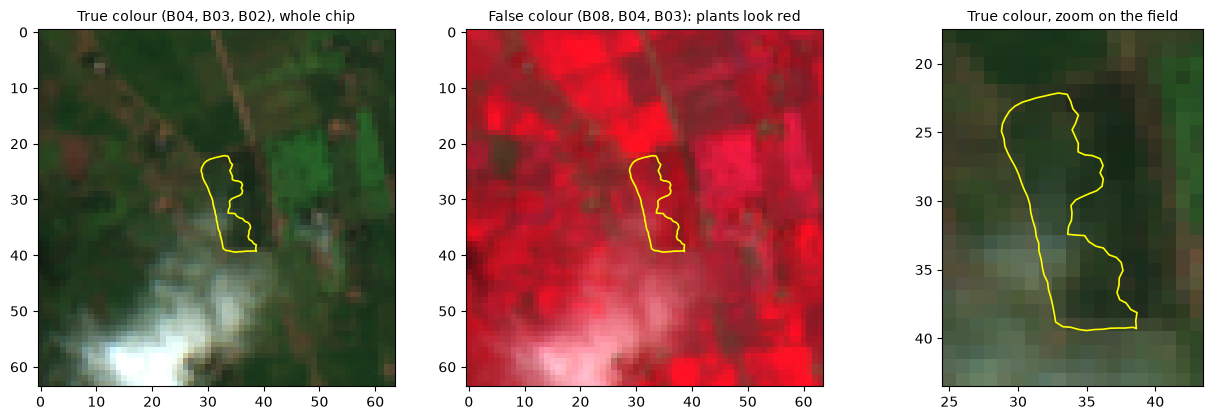

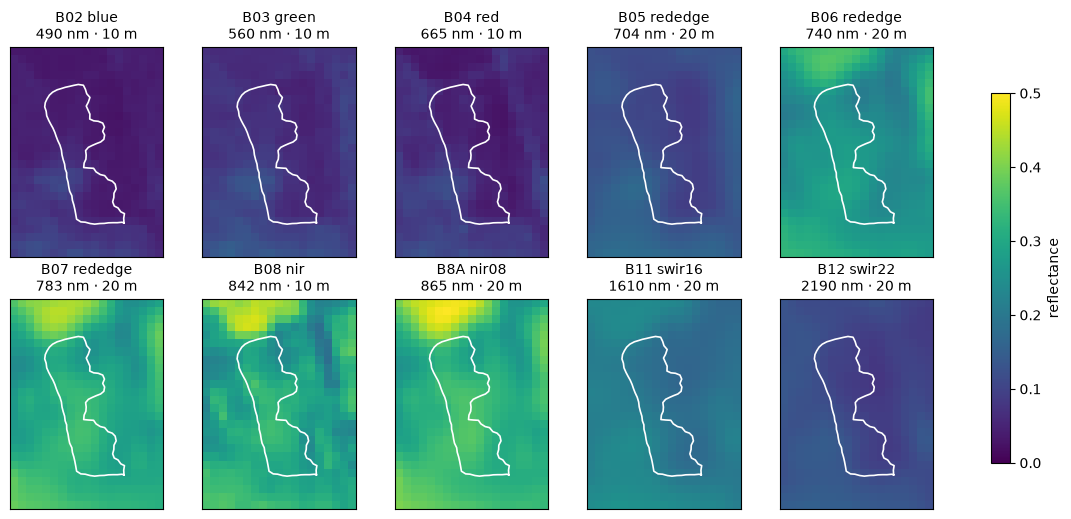

In [7]:
def composite(scene, bands=("B04", "B03", "B02"), top=0.3):
    """Three bands as an image: reflectance 0..top maps to 0..1; pixels that are not clear show white."""
    image = np.stack([scene.reflectance[chip.bands.index(b)] for b in bands], axis=-1) / top
    return np.nan_to_num(np.clip(image, 0, 1), nan=1.0)


fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))
axes[0].imshow(composite(scene))
axes[0].set_title("True colour (B04, B03, B02), whole chip")
axes[1].imshow(composite(scene, ("B08", "B04", "B03"), top=0.45))
axes[1].set_title("False colour (B08, B04, B03): plants look red")
axes[2].imshow(composite(scene))
axes[2].set(xlim=ZOOM_X, ylim=ZOOM_Y, title="True colour, zoom on the field")
for ax in axes:
    draw_outline(ax)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, code in zip(axes.flat, chip.bands):
    picture = ax.imshow(scene.reflectance[chip.bands.index(code)], cmap="viridis", vmin=0, vmax=0.5)
    draw_outline(ax, "white")
    info = band_table.loc[code]
    ax.set(xlim=ZOOM_X, ylim=ZOOM_Y, title=f"{code} {info['common_name']}\n{info['centre_nm']} nm · "
                                          f"{info['native_resolution_m']} m")
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(picture, ax=axes, shrink=0.8, label="reflectance")
plt.show()

The 20 m bands (red edge, B8A, SWIR) look blockier: the downloader puts them on the same 10 m grid by bilinear
resampling, so one 20 m pixel covers four chip pixels.

## 6. The season: every accepted scene, and the clouds

The downloader searched the catalog for every scene over this field inside the season window. For each month it
tried up to three scenes, least cloudy tile first, and accepted the first one in which at least 80 % of the field
pixels are clear (SCL class 4 vegetation, 5 bare soil or 6 water). So a month has **at most one scene**, and a
month with no accepted scene stays empty.

In [8]:
record = json.loads(Path(filesystem_path(chip.record_dir / "record.json")).read_text())
attempts = pd.DataFrame(record["attempts"])
month_log = []
for month in month_range(*season):
    tried = attempts[attempts["month"] == month] if len(attempts) else attempts
    accepted = tried[tried["status"] == "accepted"] if len(tried) else tried
    month_log.append({
        "month": month,
        "scenes_tried": len(tried),
        "best_clear_fraction": round(float(tried["clear_fraction_aoi"].max()), 2) if len(tried) else None,
        "result": (f"accepted {accepted['item_id'].iloc[0]}" if len(accepted)
                   else "no scene in the catalog" if tried.empty else "rejected: " + ", ".join(sorted(set(tried["status"])))),
    })
print(f"catalog scenes over the field in the window: {record['catalog_matches']} | accepted: {len(chip.scenes)}")
pd.DataFrame(month_log).set_index("month")

catalog scenes over the field in the window: 50 | accepted: 5


,scenes_tried,best_clear_fraction,result
month,,,
2022-10,0,NaN,no scene in the catalog
2022-11,0,NaN,no scene in the catalog
2022-12,1,1.00,accepted S2B_T36LWL_20221217T081213_L2A
2023-01,3,0.00,rejected: rejected_cloud_or_nodata
2023-02,3,0.12,rejected: rejected_cloud_or_nodata
2023-03,1,1.00,accepted S2B_T36LWL_20230307T081156_L2A
2023-04,1,0.94,accepted S2B_T36LWL_20230426T081153_L2A
2023-05,1,1.00,accepted S2B_T36LWL_20230506T081154_L2A
2023-06,1,1.00,accepted S2A_T36LWL_20230630T080627_L2A


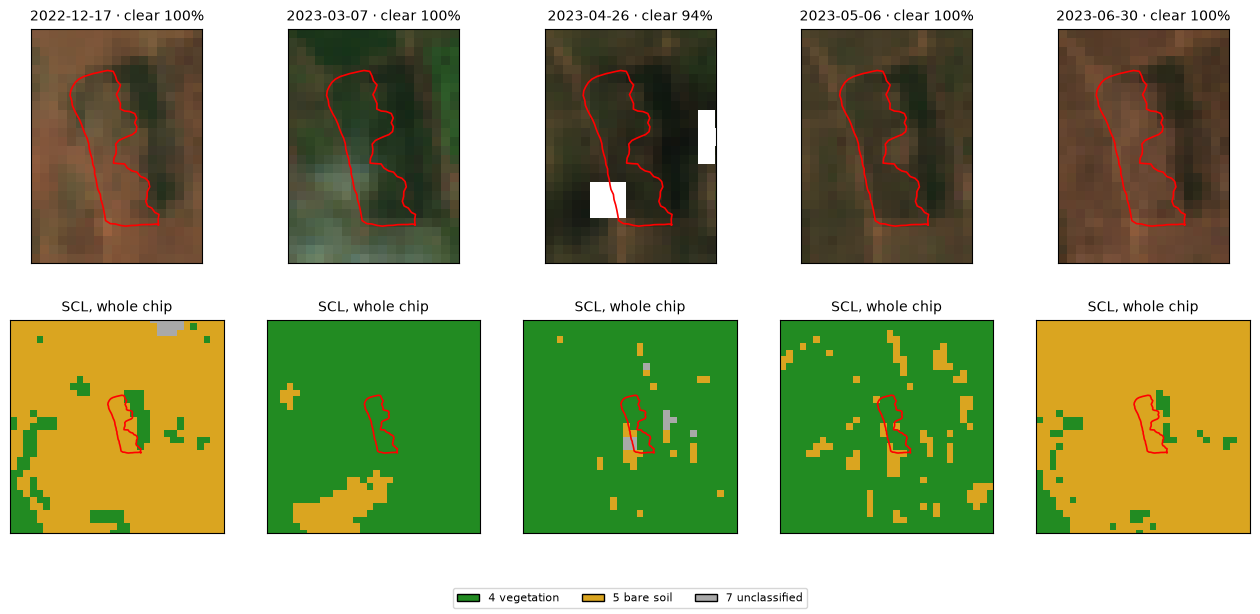

In [9]:
SCL_CLASSES = {0: ("no data", "black"), 1: ("saturated / defective", "red"), 2: ("dark area", "dimgray"),
               3: ("cloud shadow", "saddlebrown"), 4: ("vegetation", "forestgreen"), 5: ("bare soil", "goldenrod"),
               6: ("water", "royalblue"), 7: ("unclassified", "darkgray"), 8: ("cloud, medium", "lightgray"),
               9: ("cloud, high", "white"), 10: ("thin cirrus", "lightskyblue"), 11: ("snow / ice", "violet")}
scl_colours = ListedColormap([colour for _, colour in SCL_CLASSES.values()])

fig, axes = plt.subplots(2, len(chip.scenes), figsize=(3.2 * len(chip.scenes), 6.6), squeeze=False)
for i, s in enumerate(chip.scenes):
    axes[0, i].imshow(composite(s))
    axes[0, i].set(xlim=ZOOM_X, ylim=ZOOM_Y, title=f"{s.date} · clear {s.clear_fraction_aoi:.0%}")
    axes[1, i].imshow(s.scl, cmap=scl_colours, vmin=-0.5, vmax=11.5, interpolation="nearest")
    axes[1, i].set_title("SCL, whole chip")
    for ax in axes[:, i]:
        draw_outline(ax, "red")
        ax.set_xticks([])
        ax.set_yticks([])
present = sorted(set(np.unique(np.concatenate([s.scl.ravel() for s in chip.scenes])).tolist()))
fig.legend(handles=[Patch(facecolor=SCL_CLASSES[c][1], edgecolor="black", label=f"{c} {SCL_CLASSES[c][0]}")
                    for c in present], loc="lower center", ncol=len(present), fontsize=8)
plt.subplots_adjust(bottom=0.1)
plt.show()

Read the bottom row from left to right: bare soil before planting, green maize in the rainy season, bare again after
harvest. Two reasons leave a month empty: **no scene in the catalog** (Earth Search Collection 1 has almost nothing
for this tile before December 2022, `docs/DECISIONS.md`, 26 Oct) and **clouds** (January and February are the peak
of the rainy season, exactly when the crop grows).

**SCL is not a perfect cloud mask.** In the whole-chip true-colour image of 7 March (section 5), a white haze covers
the lower left of the chip, yet SCL labels those pixels vegetation or bare soil, so they count as "clear". Haze
makes the blue band bright. Clear crops and soil in this area have a blue reflectance of about 0.03–0.08, so the cell
below uses blue > 0.12 as a rough flag for an eye check. It is not a rule the pipeline applies.

In [10]:
BLUE_FLAG = 0.12


def haze_check(chip):
    """Per accepted scene: SCL's clear fraction next to the field's blue reflectance and its share of bright-blue pixels."""
    blue = chip.bands.index("B02")
    field = chip.aoi_interior
    return pd.DataFrame({
        "date": [s.date for s in chip.scenes],
        "scl_clear_fraction": [round(s.clear_fraction_aoi, 2) for s in chip.scenes],
        "field_blue_median": [round(float(np.nanmedian(s.reflectance[blue][field])), 3) for s in chip.scenes],
        "field_share_blue_over_flag": [round(float((s.reflectance[blue][field] > BLUE_FLAG).mean()), 2)
                                       for s in chip.scenes],
    })


print("this field:")
display(haze_check(chip))
flagged = []
for _, r in cohort.head(10).iterrows():
    window = (date.fromisoformat(r["season_start"]), date.fromisoformat(r["season_end"]))
    check = haze_check(find_chip(r["dataset"], r["source_id"], window))
    for _, scene_row in check[check["field_share_blue_over_flag"] > 0.1].iterrows():
        flagged.append({"field": r["source_id"][:8], "yield_kg_ha": r["yield_kg_ha"], **scene_row})
print(f"pilot scenes that SCL accepted but where more than 10 % of the field pixels have blue > {BLUE_FLAG}:")
pd.DataFrame(flagged)

this field:


,date,scl_clear_fraction,field_blue_median,field_share_blue_over_flag
0,2022-12-17,1.00,0.064,0.0
1,2023-03-07,1.00,0.041,0.0
2,2023-04-26,0.94,0.033,0.0
3,2023-05-06,1.00,0.041,0.0
4,2023-06-30,1.00,0.058,0.0


pilot scenes that SCL accepted but where more than 10 % of the field pixels have blue > 0.12:


,field,yield_kg_ha,date,scl_clear_fraction,field_blue_median,field_share_blue_over_flag
0,506ae8b2,2950.0,2023-01-13,1.0,0.114,0.18
1,10738537,2620.0,2023-03-07,1.0,0.127,0.54
2,4591d3d5,780.0,2023-02-15,1.0,0.157,0.64


Each flagged scene became one row of a monthly table as if it were clear, so its NDVI is too low for that month.
A stricter cloud check (a cloud-probability layer, or a blue or haze test on the field) is a decision for the
satellite-pipeline owner, before the full extraction.

## 7. From pixels to one table: the monthly field summary

This is the step where the **picture becomes numbers**. For each month, `monthly_series` takes the pixels that are
inside the field *and* valid in that month's scene, and keeps the **median** of each band. After this step there is
no left, right, up or down any more: one field-season is one small table. Every model except MOSAIKS starts here.

In [11]:
series = monthly_series(chip, *season)
monthly = pd.DataFrame(series.values, index=series.months, columns=series.bands)
monthly["valid_field_pixels"] = series.n_pixels
print("table shape", series.values.shape, "(months, bands) | pixel rule:", series.pixel_rule,
      "| missing months:", [m for m, gone in zip(series.months, series.missing) if gone])
monthly.round(3)

table shape (9, 10) (months, bands) | pixel rule: interior | missing months: ['2022-10', '2022-11', '2023-01', '2023-02']


,B02,B03,B04,B05,B06,B07,B08,B8A,B11,B12,valid_field_pixels
2022-10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2022-11,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2022-12,0.064,0.096,0.124,0.156,0.206,0.226,0.214,0.240,0.291,0.253,84
2023-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2023-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2023-03,0.041,0.071,0.050,0.107,0.263,0.316,0.307,0.336,0.190,0.101,84
2023-04,0.033,0.051,0.052,0.089,0.150,0.169,0.167,0.186,0.165,0.106,79
2023-05,0.041,0.063,0.070,0.118,0.182,0.203,0.207,0.226,0.234,0.160,84
2023-06,0.058,0.084,0.122,0.155,0.186,0.204,0.218,0.234,0.295,0.216,84


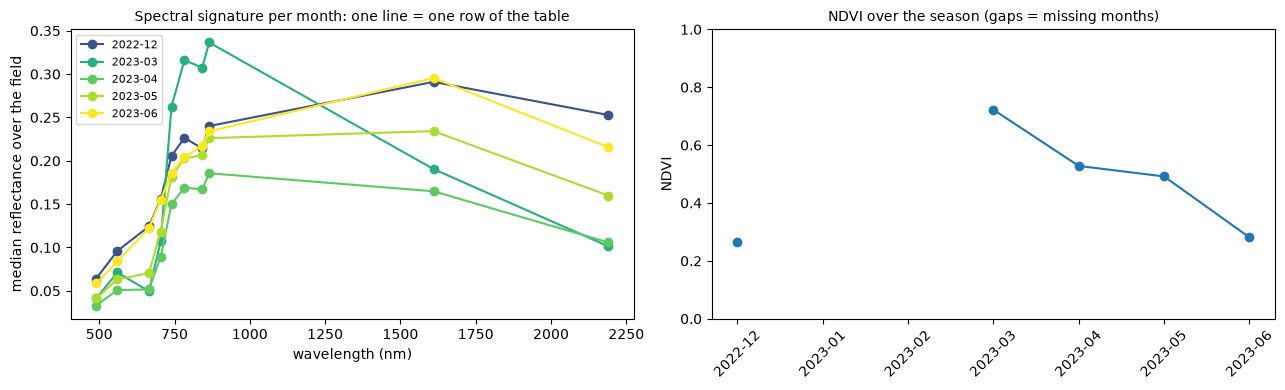

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
wavelengths = band_table["centre_nm"].astype(float).values
colours = plt.cm.viridis(np.linspace(0, 1, len(series.months)))
for month, values, gone, colour in zip(series.months, series.values, series.missing, colours):
    if not gone:
        axes[0].plot(wavelengths, values, marker="o", color=colour, label=month)
axes[0].set(xlabel="wavelength (nm)", ylabel="median reflectance over the field",
            title="Spectral signature per month: one line = one row of the table")
axes[0].legend(fontsize=8)
ndvi = (series.band("B08") - series.band("B04")) / (series.band("B08") + series.band("B04"))
axes[1].plot(series.months, ndvi, marker="o")
axes[1].set(ylim=(0, 1), ylabel="NDVI", title="NDVI over the season (gaps = missing months)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

The jump between red (665 nm) and the red edge / NIR bands (705–865 nm) is the plant signal. It is large in March
(green maize) and small in December and June (soil).

## 8. What each model receives

Same field, same table, different inputs. Each subsection builds the input for one model family.

### 8a. Location-only baseline

Only where the field is. It tells us how much of the yield is explained by place alone (soil, rain, district). The
satellite models must beat it (gate H1 in `docs/ROADMAP.md`).

In [13]:
location_input = np.array([row["latitude"], row["longitude"]])
print("location input", location_input.shape, location_input.round(5))

location input (2,) [-13.29     33.40077]


### 8b. Vegetation-index baselines (ridge, random forest, XGBoost)

Lobell et al. (2020, *AJAE*, Table 2) use five indices computed from Sentinel-2 bands. Computed for every month, they
give a months × 5 table. A ridge or tree model needs a **fixed-length vector**, so the table is summarised over the
season. Seasonal maximum and mean below are only one example; the baseline owner fixes the real summary before
training and uses the same one for every cohort.

In [14]:
def vegetation_indices(series):
    """Lobell et al. (2020) Table 2 indices for each month of a monthly series; NaN for missing months."""
    b = {code: series.band(code) for code in series.bands}
    return pd.DataFrame({
        "NDVI": (b["B08"] - b["B04"]) / (b["B08"] + b["B04"]),
        "GCVI": b["B08"] / b["B03"] - 1,
        "MTCI": (b["B08"] - b["B05"]) / (b["B05"] - b["B04"]),
        "NDVI705": (b["B08"] - b["B05"]) / (b["B08"] + b["B05"]),
        "NDVI740": (b["B08"] - b["B06"]) / (b["B08"] + b["B06"]),
    }, index=series.months)


def seasonal_summary(indices):
    """Example fixed-length features: seasonal max and mean of each index over the months with data."""
    stats = indices.agg(["max", "mean"])
    return pd.Series({f"{name}_{stat}": stats.loc[stat, name] for name in indices.columns for stat in stats.index})


indices = vegetation_indices(series)
features = seasonal_summary(indices)
print("indices per month", indices.shape, "→ feature vector", features.shape)
display(indices.round(3))
features.round(3).to_frame("value").T

indices per month (9, 5) → feature vector (10,)


,NDVI,GCVI,MTCI,NDVI705,NDVI740
2022-10,NaN,NaN,NaN,NaN,NaN
2022-11,NaN,NaN,NaN,NaN,NaN
2022-12,0.266,1.233,1.846,0.158,0.021
2023-01,NaN,NaN,NaN,NaN,NaN
2023-02,NaN,NaN,NaN,NaN,NaN
2023-03,0.722,3.316,3.490,0.483,0.078
2023-04,0.528,2.281,2.078,0.304,0.054
2023-05,0.492,2.264,1.835,0.271,0.064
2023-06,0.281,1.592,1.897,0.168,0.078


,NDVI_max,NDVI_mean,GCVI_max,GCVI_mean,MTCI_max,MTCI_mean,NDVI705_max,NDVI705_mean,NDVI740_max,NDVI740_mean
value,0.722,0.458,3.316,2.137,3.49,2.229,0.483,0.277,0.078,0.059


### 8c. GRU

A recurrent network reads the months in order, so it can take the table itself: months × bands (or months ×
indices). It cannot read NaN, so missing months need a fill value plus an "observed" flag, or must be skipped.
That choice belongs to the GRU owner.

In [15]:
sequence, observed = series.values, ~series.missing
print("sequence", sequence.shape, "(months, bands) | observed", observed.astype(int))

sequence (9, 10) (months, bands) | observed [0 0 1 0 0 1 1 1 1]


### 8d. MOSAIKS

MOSAIKS starts from the **images**, not from the table. It draws K small random patches (for example 3 × 3 pixels ×
10 bands) from training images, slides each one over an image as a filter, applies a ReLU and averages over the
pixels: K numbers per image. A ridge regression maps those K numbers to yield. It is the only branch that keeps
texture and neighbourhood. Two choices are still open: the whole 640 m chip (neighbouring fields included) or only
the field pixels, and one month or several.

In [16]:
images = np.stack([s.reflectance for s in chip.scenes])
print("MOSAIKS input for this field", images.shape, "(scenes, bands, rows, columns)")

MOSAIKS input for this field (5, 10, 64, 64) (scenes, bands, rows, columns)


### 8e. Presto

`presto_inputs` turns the monthly table into the four tensors that Presto expects:

* `x` (1, months, 17): our 10 bands and NDVI in Presto's 17 slots. Sentinel-1, weather and elevation slots are 0.
* `mask` (1, months, 17): 1 = "ignore this value". It is 1 for every slot we do not have and for every missing month.
* `latlons` (1, 2) and `month` (index of the first month, January = 0): the context the 3D explorer shows on top.
* `dynamic_world` (1, months): all 9 ("unknown"), so Presto drops those tokens.

x (1, 9, 17) | mask (1, 9, 17) | latlons [[-13.289999961853027, 33.40079879760742]] | month 9 (2022-10)


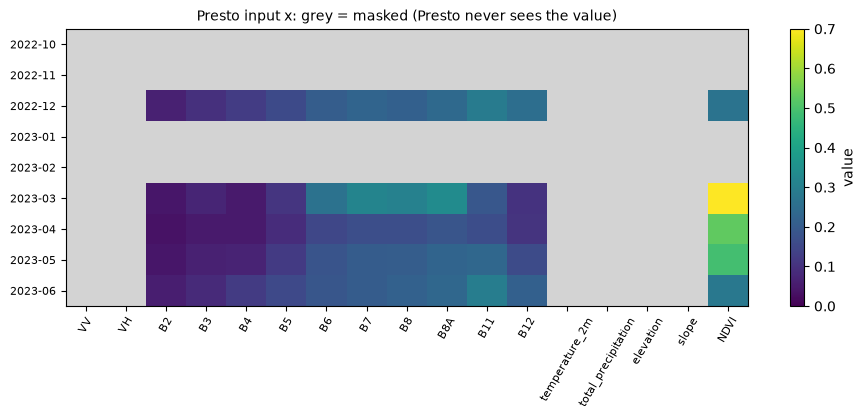

In [17]:
inputs = presto_inputs(series, row["latitude"], row["longitude"])
print("x", inputs.x.shape, "| mask", inputs.mask.shape, "| latlons", inputs.latlons.round(4).tolist(),
      "| month", inputs.month, f"({inputs.months[0]})")

fig, ax = plt.subplots(figsize=(11, 3.6))
shown = np.ma.masked_where(inputs.mask[0] == 1, inputs.x[0])
cmap = plt.cm.viridis.copy()
cmap.set_bad("lightgrey")
picture = ax.imshow(shown, cmap=cmap, aspect="auto", vmin=0, vmax=0.7)
ax.set_xticks(range(len(NORMED_BANDS)), NORMED_BANDS, rotation=60, fontsize=8)
ax.set_yticks(range(len(inputs.months)), inputs.months, fontsize=8)
ax.set_title("Presto input x: grey = masked (Presto never sees the value)")
fig.colorbar(picture, ax=ax, label="value")
plt.show()

Inside the encoder, every month is cut into **band groups**, and each group that has no masked value becomes one
token. The grid below repeats the encoder's rule (a group is dropped if any of its slots is masked; elevation is one
token for the whole season). The cell then runs the real encoder and checks that the token count matches.

In [18]:
token_grid = {}
for group, slots in BANDS_GROUPS_IDX.items():
    kept = inputs.mask[0][:, slots].max(axis=1) == 0
    token_grid[group] = kept[:1] if group == "SRTM" else kept
token_grid["dynamic_world"] = inputs.dynamic_world[0] != MISSING_DYNAMIC_WORLD
grid = pd.DataFrame({g: pd.Series(k, index=inputs.months[:len(k)]) for g, k in token_grid.items()}).T
expected = int(grid.fillna(False).to_numpy(dtype=bool).sum()) + 1  # + 1 location token

model = load_presto()
with torch.no_grad():
    tokens, kept_indices, removed_indices = model.encoder(**to_tensors(inputs), eval_task=False)
print(f"tokens by rule: {expected} | tokens out of the real encoder: {tokens.shape[1]} | each token: {tokens.shape[2]} numbers")
assert tokens.shape[1] == expected
grid.replace({True: "token", False: ""}).fillna("")

tokens by rule: 31 | tokens out of the real encoder: 31 | each token: 128 numbers


,2022-10,2022-11,2022-12,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06
S1,,,,,,,,,
S2_RGB,,,token,,,token,token,token,token
S2_Red_Edge,,,token,,,token,token,token,token
S2_NIR_10m,,,token,,,token,token,token,token
S2_NIR_20m,,,token,,,token,token,token,token
S2_SWIR,,,token,,,token,token,token,token
ERA5,,,,,,,,,
SRTM,,,,,,,,,
NDVI,,,token,,,token,token,token,token
dynamic_world,,,,,,,,,


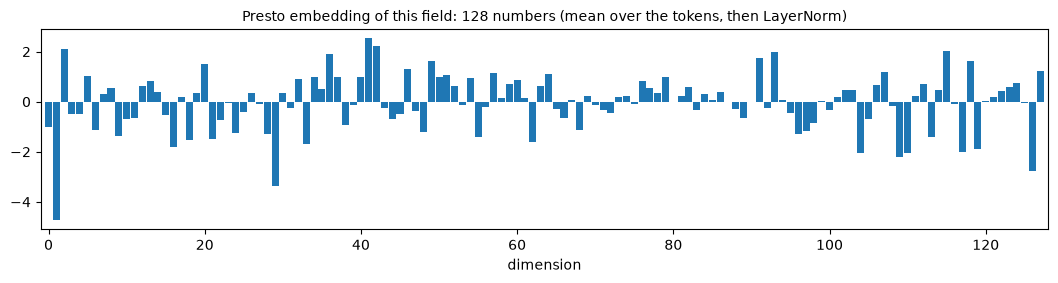

In [19]:
embedding = encode(model, inputs)
fig, ax = plt.subplots(figsize=(13, 2.6))
ax.bar(range(len(embedding)), embedding, width=0.9)
ax.set(xlim=(-1, len(embedding)), xlabel="dimension", title=f"Presto embedding of this field: {embedding.shape[0]} numbers "
                                                            "(mean over the tokens, then LayerNorm)")
plt.show()

A single dimension has no meaning on its own. The embedding is useful only through distances between fields and
through a model trained on top of it.

### Summary: the input of every model for this one field

In [20]:
pd.DataFrame([
    ("Location-only baseline", "latitude, longitude", location_input.shape, "ridge or tree on 2 numbers"),
    ("Vegetation-index baseline", "seasonal summary of 5 indices", features.shape, "ridge, random forest, XGBoost"),
    ("GRU", "monthly band table + observed flag", sequence.shape, "GRU weights and a head"),
    ("MOSAIKS", "the chip images", images.shape, "ridge on K random features (the features are fixed)"),
    ("Presto, frozen", "Presto embedding", embedding.shape, "ridge or a linear head: 128 weights + 1"),
    ("Presto, fine-tuned", "x, mask, latlons, month", inputs.x.shape, "the whole encoder and the head"),
], columns=["model", "input", "shape for this field", "what learns"]).set_index("model")

,input,shape for this field,what learns
model,,,
Location-only baseline,"latitude, longitude","(2,)",ridge or tree on 2 numbers
Vegetation-index baseline,seasonal summary of 5 indices,"(10,)","ridge, random forest, XGBoost"
GRU,monthly band table + observed flag,"(9, 10)",GRU weights and a head
MOSAIKS,the chip images,"(5, 10, 64, 64)",ridge on K random features (the features are f...
"Presto, frozen",Presto embedding,"(128,)",ridge or a linear head: 128 weights + 1
"Presto, fine-tuned","x, mask, latlons, month","(1, 9, 17)",the whole encoder and the head


## 9. What stays fixed and what learns

| | chip → monthly table → `x` | Presto encoder | embedding | model on top |
|---|---|---|---|---|
| Vegetation-index baselines | fixed | not used | not used | learns |
| Presto frozen + ridge (week 1) | fixed | **fixed** | computed once, cached | learns |
| Presto fine-tuned (LP-FT, week 3) | fixed | **learns** | changes at every step | learns |

The images and the tables never change. With frozen Presto, a simple loop computes every embedding once, and ridge
runs on a table; no DataLoader is needed. Only fine-tuning changes the encoder, so the embeddings must be recomputed
in every training step. That is where a `Dataset` and a `DataLoader` come in. The regression head the 3D explorer
shows is `model.construct_finetuning_model(num_outputs=1, regression=True)`: one linear layer, 128 → 1.

## 10. The modelling table for the ten pilot fields

The same steps for every pilot field give the tables the models read: one row per field, a label column, and the
feature columns. **Ten rows are far too few to fit anything**; this only shows the shape.

In [21]:
pilot = cohort.head(10).set_index("obs_id")
table, embeddings = [], []
for obs_id, r in pilot.iterrows():
    window = (date.fromisoformat(r["season_start"]), date.fromisoformat(r["season_end"]))
    s = monthly_series(find_chip(r["dataset"], r["source_id"], window), *window)
    table.append({"obs_id": obs_id, "yield_kg_ha": r["yield_kg_ha"], "latitude": r["latitude"],
                  "longitude": r["longitude"], "months_with_data": int((~s.missing).sum()),
                  **seasonal_summary(vegetation_indices(s))})
    embeddings.append(encode(model, presto_inputs(s, r["latitude"], r["longitude"])))
modelling = pd.DataFrame(table).set_index("obs_id")
y = modelling["yield_kg_ha"]
X_location = modelling[["latitude", "longitude"]]
X_indices = modelling.filter(regex="_(max|mean)$")
X_presto = pd.DataFrame(np.stack(embeddings), index=modelling.index).add_prefix("presto_")
print("y", y.shape, "| X_location", X_location.shape, "| X_indices", X_indices.shape, "| X_presto", X_presto.shape)
modelling.round(3)

y (10,) | X_location (10, 2) | X_indices (10, 10) | X_presto (10, 128)


,yield_kg_ha,latitude,longitude,months_with_data,NDVI_max,NDVI_mean,GCVI_max,GCVI_mean,MTCI_max,MTCI_mean,NDVI705_max,NDVI705_mean,NDVI740_max,NDVI740_mean
obs_id,,,,,,,,,,,,,,
malawi_2023:506ae8b2-d085-4eeb-b807-765e03925c71,2950.0,-13.317,33.384,5,0.618,0.420,2.870,1.886,3.155,2.196,0.409,0.256,0.085,0.061
malawi_2023:626290f6-99b2-4a44-b233-8df0e13d3e63,2300.0,-13.322,33.368,4,0.729,0.499,3.385,2.487,3.031,2.245,0.464,0.301,0.076,0.064
malawi_2023:10738537-aded-4abe-bc18-e3d8ce52f7f7,2620.0,-13.291,33.401,5,0.569,0.401,2.630,1.850,2.682,2.035,0.331,0.238,0.083,0.058
malawi_2023:1d60c29e-ee3a-4639-9e07-0239523dfc62,3310.0,-13.290,33.401,5,0.722,0.458,3.316,2.137,3.490,2.229,0.483,0.277,0.078,0.059
malawi_2023:6fa8a978-4710-469b-b593-e100746035dd,4510.0,-13.302,33.403,5,0.786,0.498,4.101,2.335,3.325,2.394,0.512,0.308,0.084,0.056
malawi_2023:79ff56b9-ea86-438b-ad8b-6859295353db,2880.0,-13.298,33.403,6,0.669,0.474,2.575,1.987,3.095,2.119,0.414,0.279,0.077,0.057
malawi_2023:c3ca5a86-2c24-4c45-a762-9c766fb0fb1d,3450.0,-13.295,33.394,6,0.775,0.504,3.989,2.561,4.288,2.494,0.514,0.315,0.088,0.071
malawi_2023:4591d3d5-8258-4a9e-a8db-ad1024acb672,780.0,-13.295,33.404,7,0.683,0.462,2.519,1.806,2.828,2.035,0.381,0.265,0.084,0.047
malawi_2023:711f3b9b-a6f7-4876-aeaf-5062b5ac688f,2930.0,-13.295,33.394,6,0.705,0.506,2.988,2.403,3.363,2.137,0.468,0.297,0.098,0.072


## 11. Open data questions this tour shows

* **Missing months.** Oct–Nov 2022 are not in Earth Search Collection 1, and Jan–Feb are cloudy. Decide: also search
  `sentinel-2-pre-c1-l2a`, accept the masks, or both (`docs/DECISIONS.md`).
* **Haze that SCL misses.** Some accepted scenes are hazy over the field (section 6). Add a stricter cloud check
  before the full extraction.
* **Points versus polygons.** Kenya and Zimbabwe have points only: one pixel or a 3 × 3 neighbourhood?
* **Label quality.** The two Malawi 2023 cuts give a rough noise ceiling; Zimbabwe 2024 needs a check of its zeros.
* **Domain shift.** Presto was pretrained on L1C top-of-atmosphere data; our chips are L2A (`docs/DECISIONS.md`).
* **Fixed choices before training.** The seasonal summary for the index baselines, the MOSAIKS input (chip or field,
  one month or several), the GRU fill rule, and the spatial split files.